# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [31]:
# Lectura datos, relación variables, mapas de correlación...

In [32]:
df = pd.read_csv("data/Advertising.csv")
df= df.drop(columns=["Unnamed: 0"])
df

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0
...,...,...,...,...
195,38.2,3.7,13.8,7600.0
196,94.2,4.9,8.1,9700.0
197,177.0,9.3,6.4,12800.0
198,283.6,42.0,66.2,25500.0


In [33]:
df.loc[df["newpaper"] == "6s9.2", "newpaper"] = "69.2"

In [34]:
df["newpaper"] = pd.to_numeric(df["newpaper"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    float64
 3   sales     200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


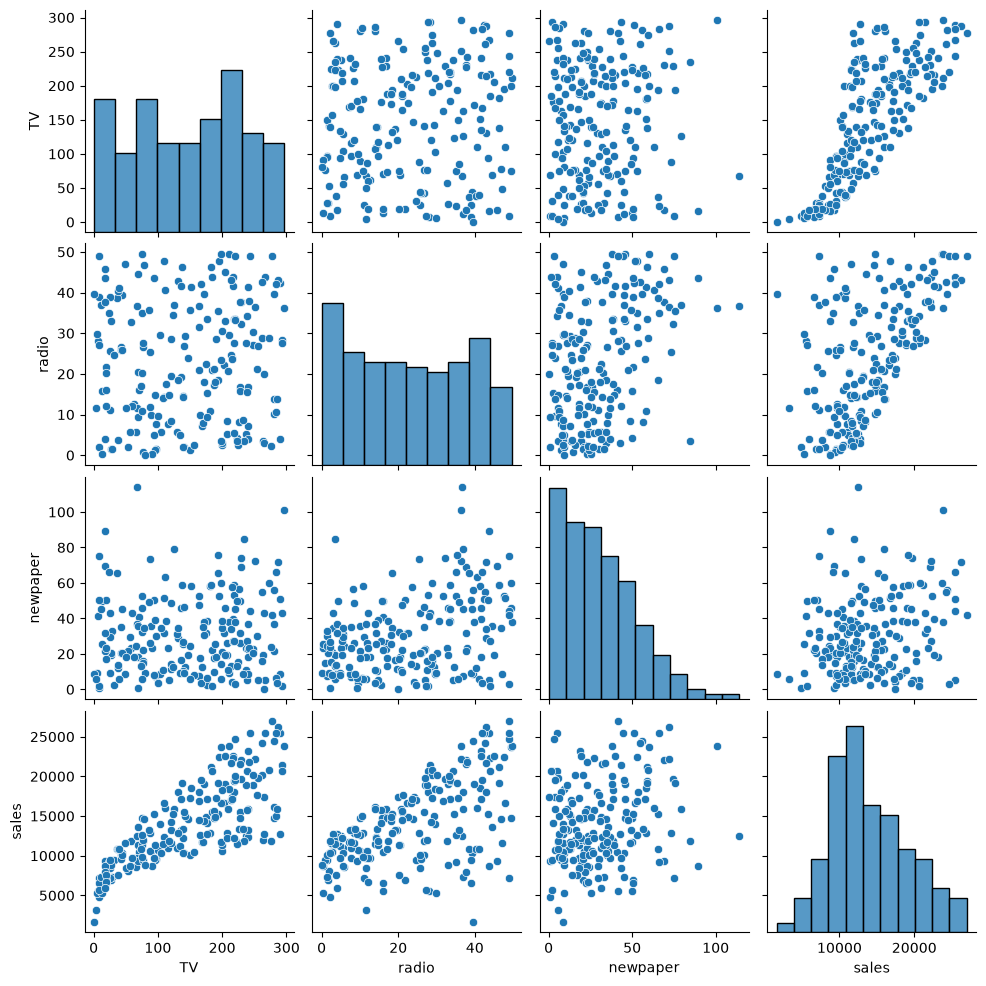

In [35]:
sns.pairplot(df)

<Axes: >

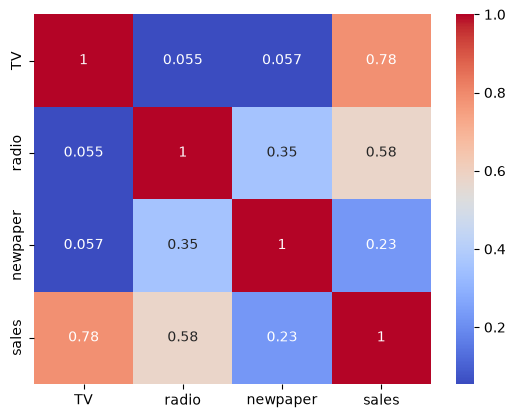

In [36]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

## Modelado

In [37]:
X = df[["TV", "newpaper", "radio"]]
y = df["sales"]

In [38]:
df.describe()

,TV,radio,newpaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14022.500000
std,85.854236,14.846809,21.778621,5217.456566
min,0.700000,0.000000,0.300000,1600.000000
25%,74.375000,9.975000,12.750000,10375.000000
50%,149.750000,22.900000,25.750000,12900.000000
75%,218.825000,36.525000,45.100000,17400.000000
max,296.400000,49.600000,114.000000,27000.000000


In [39]:
from sklearn import linear_model, metrics, model_selection
from sklearn.linear_model import ElasticNet
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) 

In [41]:
from sklearn import preprocessing
from sklearn import metrics

std_scale = preprocessing.StandardScaler().fit(X_train)
X_train_scal = std_scale.transform(X_train)
X_test_scal = std_scale.transform(X_test)

lr = linear_model.LinearRegression()
lr.fit(X_train_scal, y_train)

y_pred = lr.predict(X_test_scal)
baseline_error = metrics.mean_squared_error(y_test, y_pred)

print("Train MSE:", metrics.mean_squared_error(y_train, lr.predict(X_train_scal)))
print("Test MSE:", metrics.mean_squared_error(y_test, lr.predict(X_test_scal)))
print('RMSE test:', np.sqrt(metrics.mean_squared_error(y_test, lr.predict(X_test_scal))))
print("R2 score train:", lr.score(X_train_scal, y_train))
print("R2 score test:", lr.score(X_test_scal, y_test))

Train MSE: 2705129.4230814143
Test MSE: 3174097.353976104
RMSE test: 1781.59966153345
R2 score train: 0.8957008271017817
R2 score test: 0.899438024100912


Vemos que no hay overfit, por lo tanto, se podría usar este modelo y estaríamos seguros de que funcionaría bien.

In [42]:
n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas) 
print(np.min(alphas))
print(np.max(alphas))
alphas

0.0001
1000.0


array([1.00000000e-04, 1.17681195e-04, 1.38488637e-04, 1.62975083e-04,
       1.91791026e-04, 2.25701972e-04, 2.65608778e-04, 3.12571585e-04,
       3.67837977e-04, 4.32876128e-04, 5.09413801e-04, 5.99484250e-04,
       7.05480231e-04, 8.30217568e-04, 9.77009957e-04, 1.14975700e-03,
       1.35304777e-03, 1.59228279e-03, 1.87381742e-03, 2.20513074e-03,
       2.59502421e-03, 3.05385551e-03, 3.59381366e-03, 4.22924287e-03,
       4.97702356e-03, 5.85702082e-03, 6.89261210e-03, 8.11130831e-03,
       9.54548457e-03, 1.12332403e-02, 1.32194115e-02, 1.55567614e-02,
       1.83073828e-02, 2.15443469e-02, 2.53536449e-02, 2.98364724e-02,
       3.51119173e-02, 4.13201240e-02, 4.86260158e-02, 5.72236766e-02,
       6.73415066e-02, 7.92482898e-02, 9.32603347e-02, 1.09749877e-01,
       1.29154967e-01, 1.51991108e-01, 1.78864953e-01, 2.10490414e-01,
       2.47707636e-01, 2.91505306e-01, 3.43046929e-01, 4.03701726e-01,
       4.75081016e-01, 5.59081018e-01, 6.57933225e-01, 7.74263683e-01,
      

In [43]:
coef_ridge = []
err_ridge = []
baseline = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scal, y_train)
    
    coef_ridge.append(ridge.coef_) # guarda el coeficiente
    
    y_pred = ridge.predict(X_test_scal) 
    ridge_error = metrics.mean_squared_error(y_pred, y_test)
    
    err_ridge.append(ridge_error) # guarda el error
    baseline.append(baseline_error) # guarda el valor original (media original)

In [44]:
min(err_ridge)

3174099.2809461346

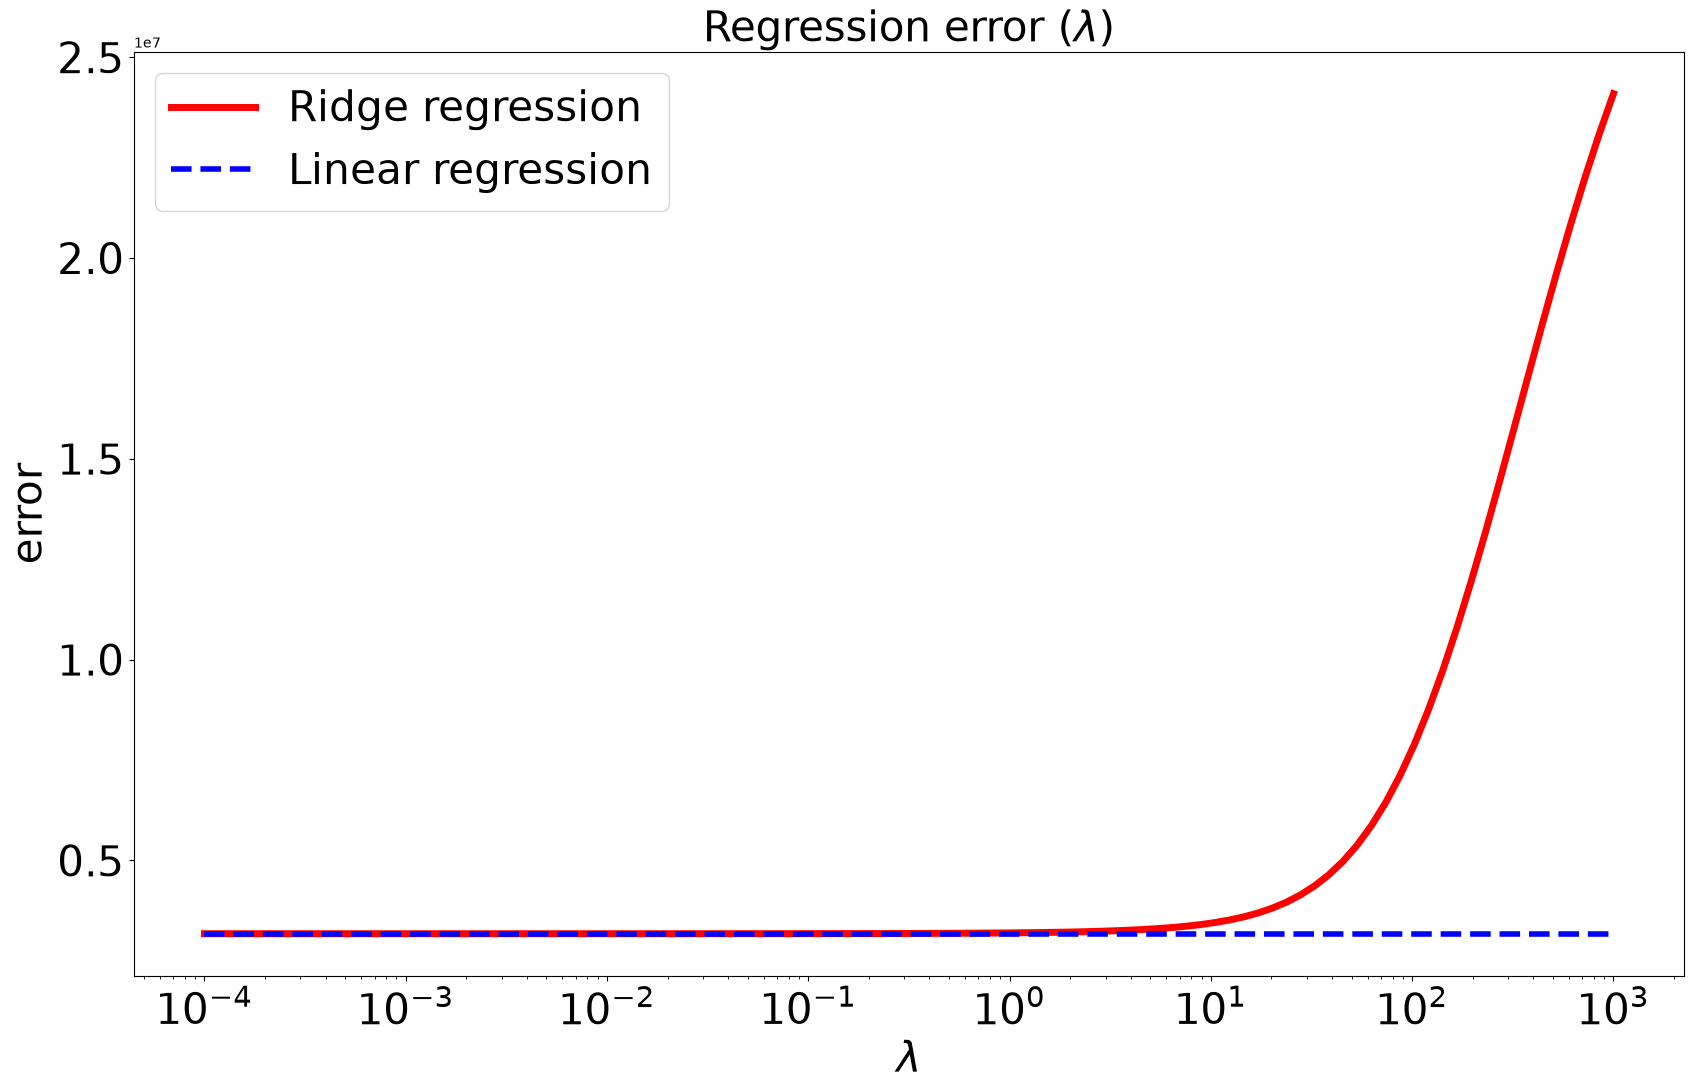

In [45]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

Mmmmmm no hay Ridge al que error haya bajado :(
La lineal es mejor. No hay ridge al que mejore.

In [46]:
lasso = linear_model.Lasso()

coef_lasso = []
err_lasso = []

for a in alphas:
    lasso.set_params(alpha=a)
    lasso.fit(X_train_scal, y_train)
    coef_lasso.append(lasso.coef_)
    y_pred = lasso.predict(X_test_scal)
    lasso_error = metrics.mean_squared_error(y_pred, y_test)    
    err_lasso.append(lasso_error)

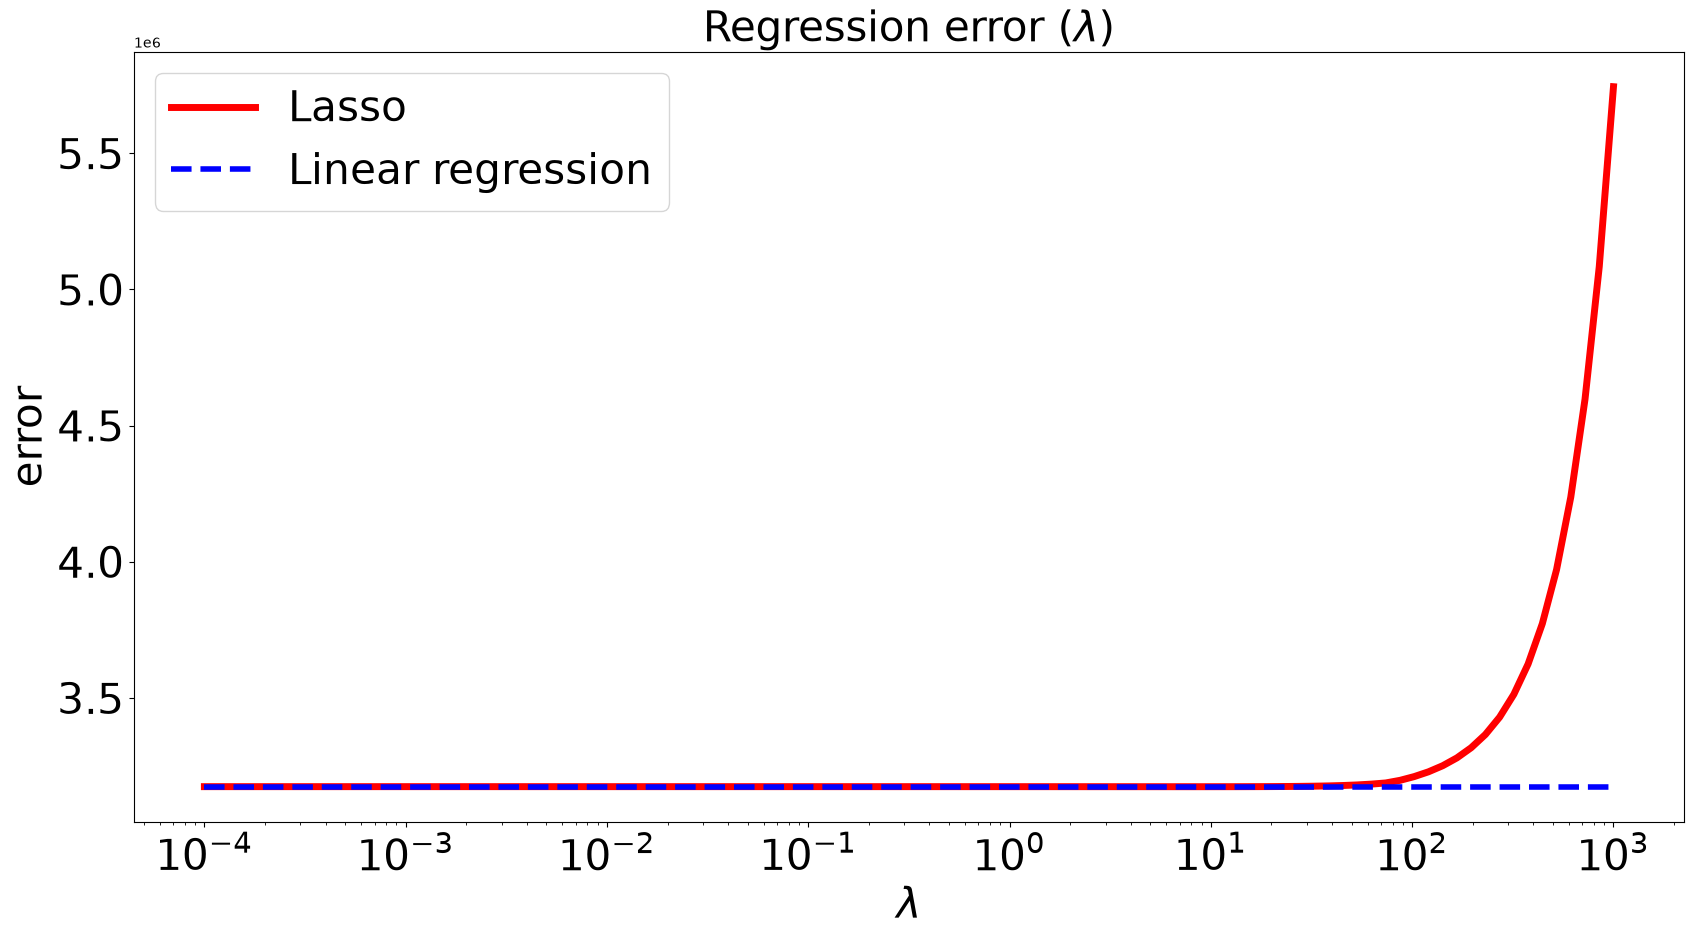

In [47]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_lasso, linewidth=5, color='red', label="Lasso")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

Esto es una mierda porque es sobre una regresión lineal.
:(((((((((((((((

No aportan nada porque no había overfit.

### Modelos Polinómicos

In [48]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

poly_feats = PolynomialFeatures(degree = 2)
poly_feats.fit(X_train_scal) # sólo train, así no le pasamos info del test
X_train_poly = poly_feats.transform(X_train_scal)
X_test_poly = poly_feats.transform(X_test_scal) 
lin_reg_2 = LinearRegression()
lin_reg_2.fit(X_train_poly, y_train)

predictions_y_test = lin_reg_2.predict(X_test_poly)

print("MAE:", mean_absolute_error(y_test, predictions_y_test))
print("MAPE:", mean_absolute_percentage_error(y_test, predictions_y_test))
print("MSE:", mean_squared_error(y_test, predictions_y_test))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions_y_test)))
print("r2_score train", lin_reg_2.score(X_train_poly, y_train))
print("r2_score test",lin_reg_2.score(X_test_poly, y_test))

MAE: 526.1794444043738
MAPE: 0.04893877124817132
MSE: 412910.2285379015
RMSE: 642.5809120553624
r2_score train 0.986104518792419
r2_score test 0.9869181490609604


Vemos nuevamente que no hay overfit, por lo que no esperamos mejoría con ridge y lasso.

In [49]:
baseline_error_poly = metrics.mean_squared_error(y_test, lin_reg_2.predict(X_test_poly))

In [50]:
coef_ridge = []
err_ridge_poly = []
baseline = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_poly, y_train)
    
    coef_ridge.append(ridge.coef_) # guarda el coeficiente
    
    y_pred = ridge.predict(X_test_poly) 
    ridge_error = metrics.mean_squared_error(y_pred, y_test)
    
    err_ridge_poly.append(ridge_error) # guarda el error
    baseline.append(baseline_error_poly) # guarda el valor original (media original)

In [51]:
min(err_ridge_poly)

412623.65769572125

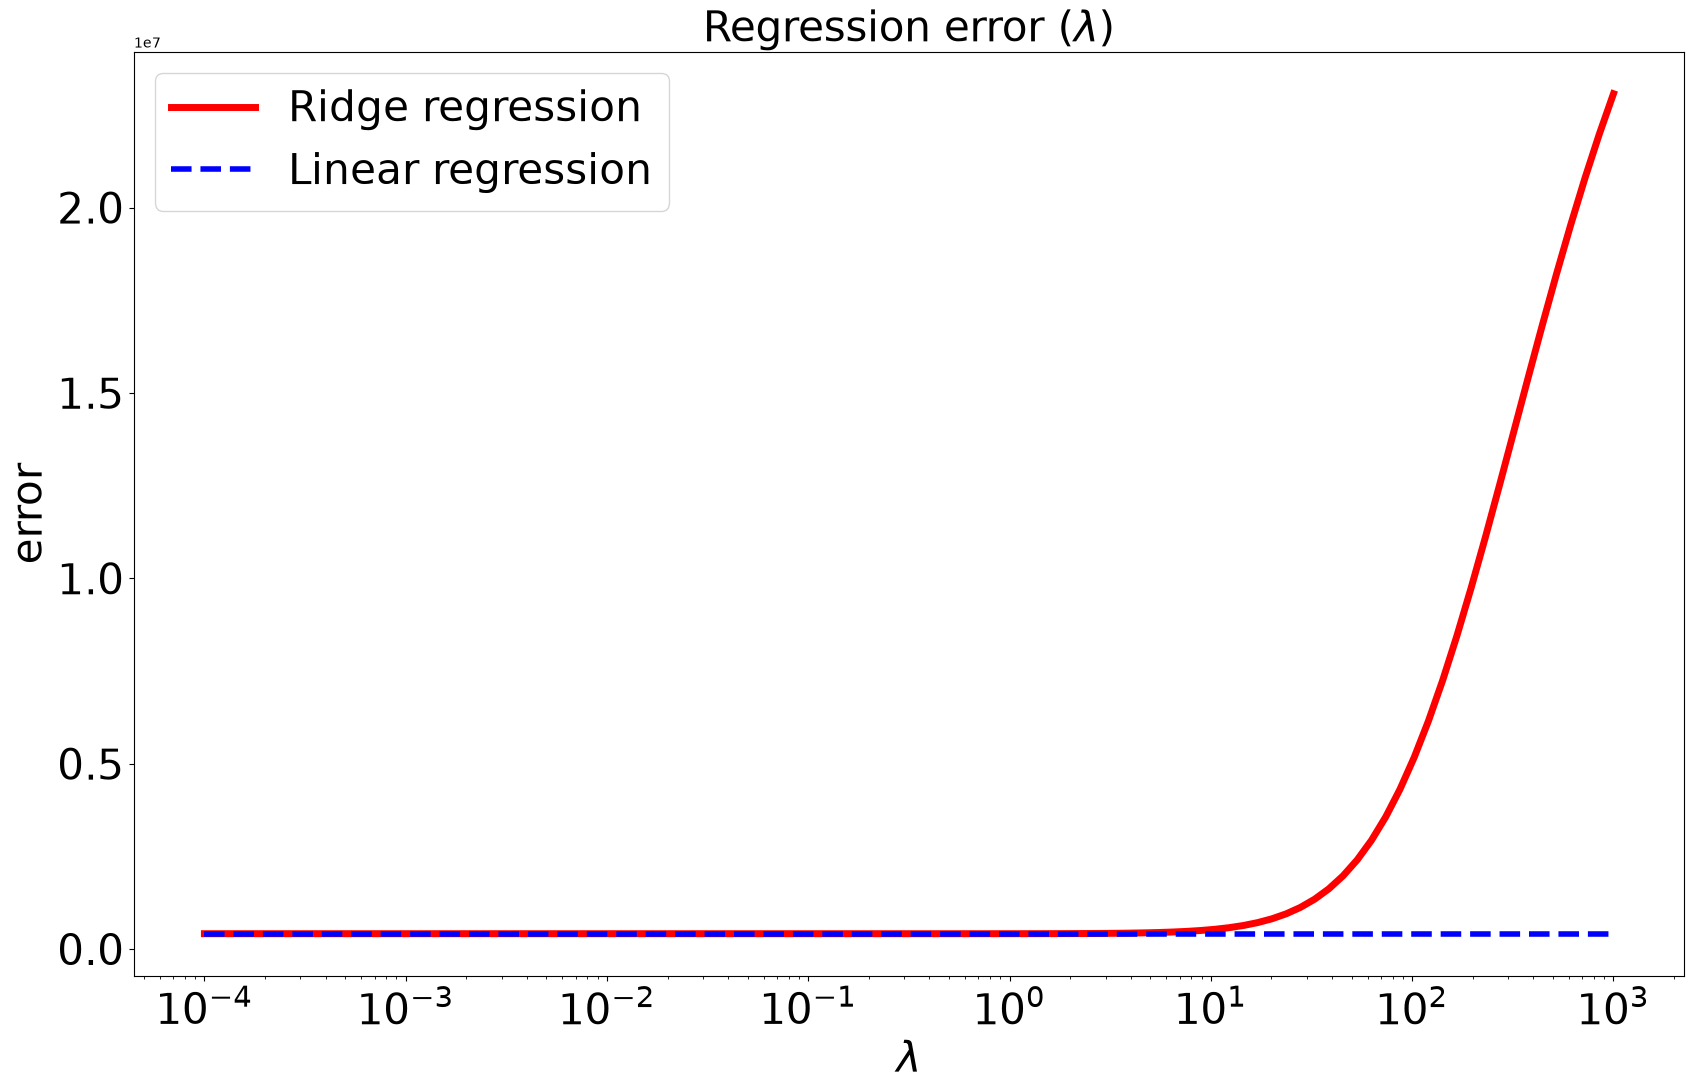

In [52]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge_poly, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [53]:
lasso = linear_model.Lasso()

coef_lasso = []
err_lasso_poly = []

for a in alphas:
    lasso.set_params(alpha=a)
    lasso.fit(X_train_poly, y_train)
    coef_lasso.append(lasso.coef_)
    y_pred = lasso.predict(X_test_poly)
    lasso_error_poly = metrics.mean_squared_error(y_pred, y_test)    
    err_lasso_poly.append(lasso_error_poly)

In [54]:
min(err_lasso_poly)

374322.79384315695

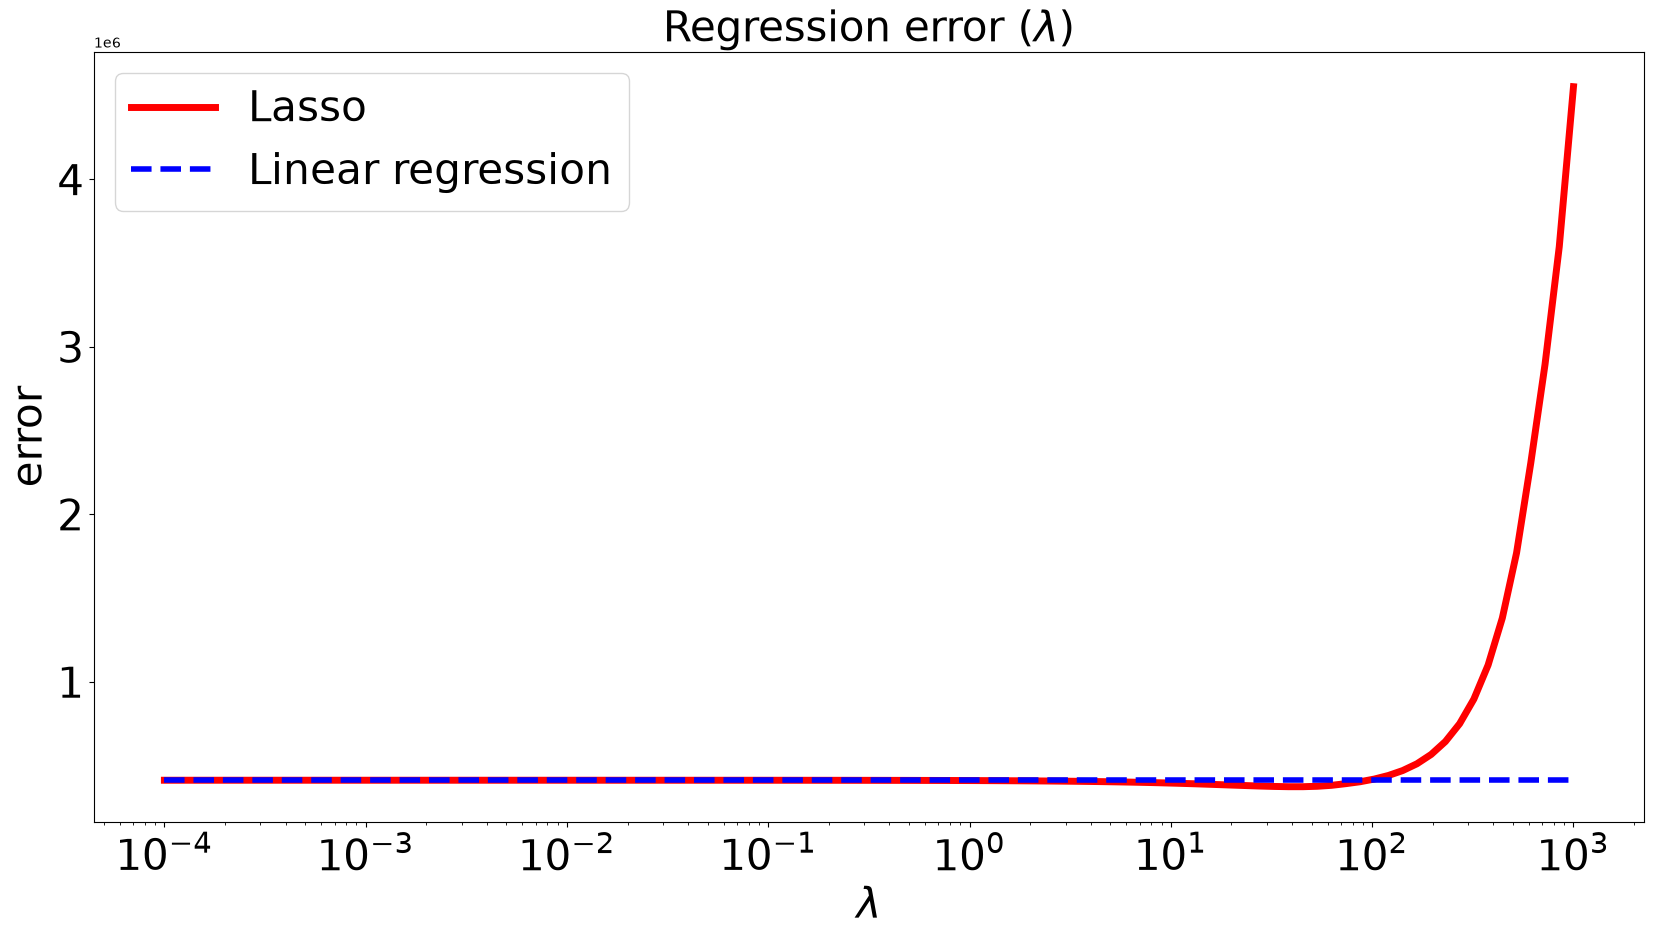

In [55]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_lasso_poly, linewidth=5, color='red', label="Lasso")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [56]:
coef_eln = []
err_eln_poly = []
baseline = []

for a in alphas:
    elastic_net = ElasticNet(alpha = a, l1_ratio=0.5)
    elastic_net.fit(X_train_poly, y_train)
    coef_eln.append(elastic_net.coef_)
    y_pred = elastic_net.predict(X_test_poly)
    elasticnet_error_poly = metrics.mean_squared_error(y_pred, y_test)
    err_eln_poly.append(elasticnet_error_poly)
    baseline.append(baseline_error_poly)

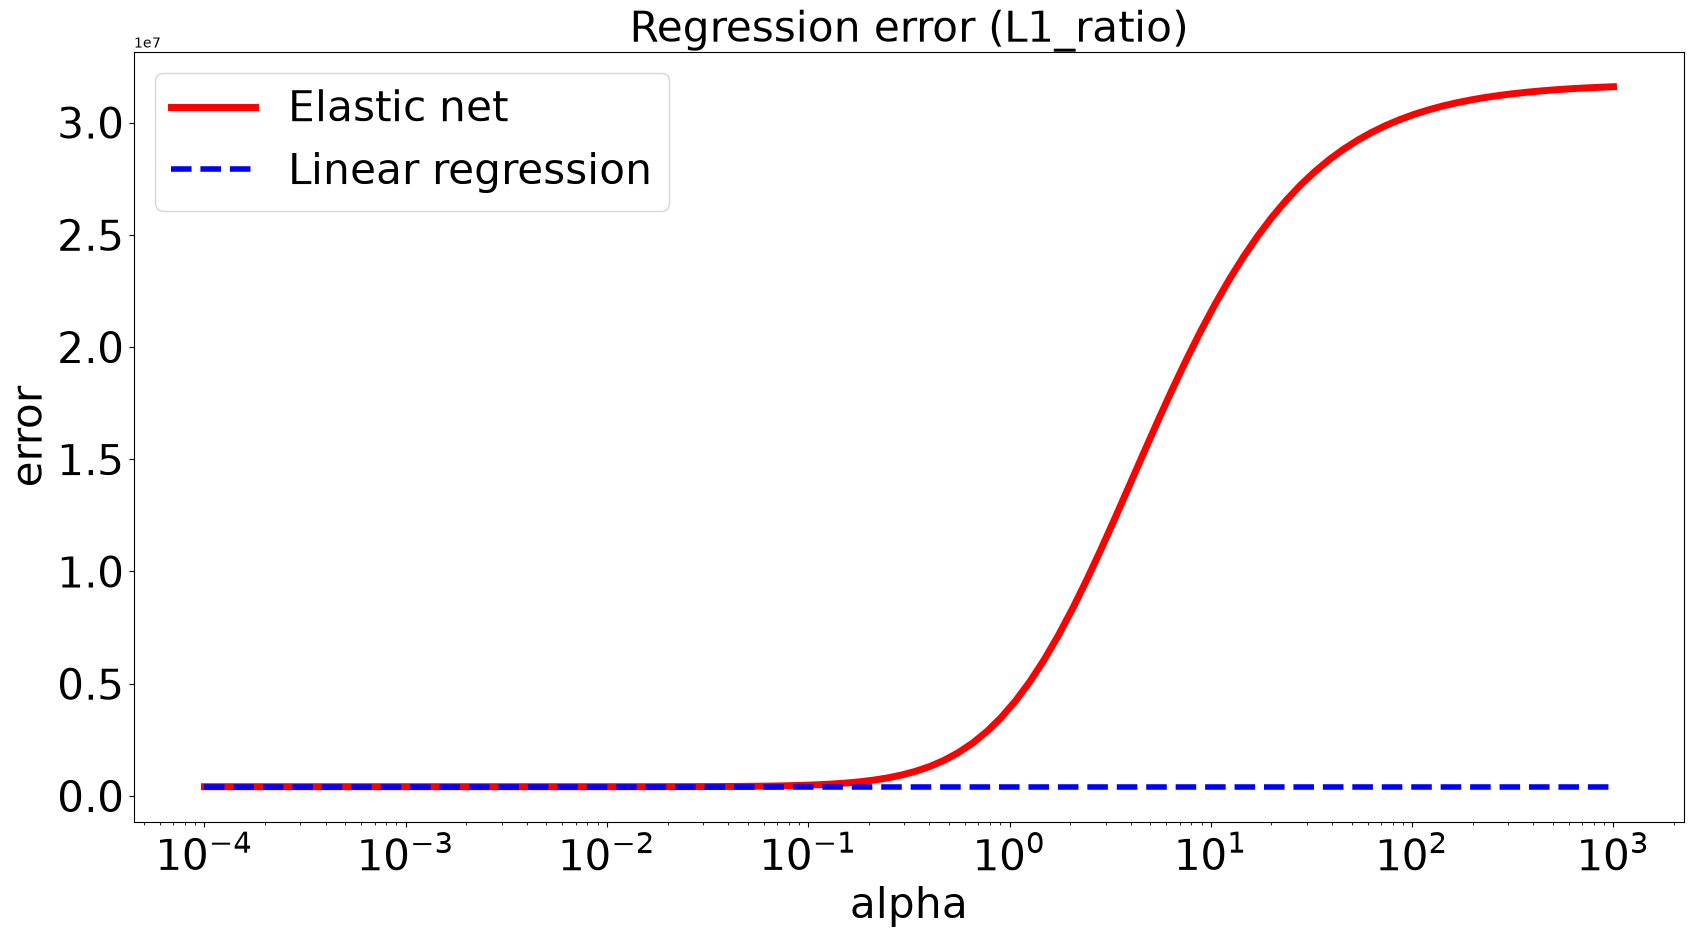

In [57]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_eln_poly, linewidth=5, color='red', label="Elastic net")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel('alpha', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error (L1_ratio)', fontsize=30)
plt.show()

## Resultados

In [58]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [59]:
print("Linear regression error:      %0.4f" % baseline_error)    
print("Minimun ridge error:          %0.4f" % min(err_ridge))
print("Minimum lasso error:          %0.4f" % min(err_lasso))
print()
print("Polynomial regression error:  %0.4f" % baseline_error_poly) 
print("Minimun ridge error:          %0.4f" % min(err_ridge_poly))
print("Minimum lasso error:          %0.4f" % min(err_lasso_poly))
print("Minimum elastic net error:    %0.4f" % min(err_eln_poly))

Linear regression error:      3174097.3540
Minimun ridge error:          3174099.2809
Minimum lasso error:          3173903.9944

Polynomial regression error:  412910.2285
Minimun ridge error:          412623.6577
Minimum lasso error:          374322.7938
Minimum elastic net error:    412618.1293


El mínimo error obtenido es en Lasso, con una polinómica de grado 2.

In [60]:
# saco el alfa correspondiente al error mínimo
alphas[err_lasso_poly.index(min(err_lasso_poly))]

np.float64(38.53528593710527)

In [61]:
lassoR = Lasso(alpha=38.53)
lassoR.fit(X_train_poly, y_train)

print("Train MSE sin regularización:", round(metrics.mean_squared_error(y_train, lin_reg_2.predict(X_train_poly)),2))
print("Test MSE sin regularización:", round(metrics.mean_squared_error(y_test, lin_reg_2.predict(X_test_poly)),2))

print("Train MSE: %0.4f" % metrics.mean_squared_error(y_train, lassoR.predict(X_train_poly)))
print("Test MSE: %0.4f" % metrics.mean_squared_error(y_test, lassoR.predict(X_test_poly)))

Train MSE sin regularización: 360396.67
Test MSE sin regularización: 412910.23
Train MSE: 372669.4894
Test MSE: 374323.5272
